## 1. Load and split the data

In [1]:
import csv
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import itertools
from helpers import create_csv_submission, load_csv_data

# Set the default plotting parameters for matplotlib.
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.bbox": "tight",
    }
)

ROOT = Path.cwd() # The root directory of the project.
DATA = ROOT / "dataset" # The directory containing the dataset files.
RESULTS = ROOT / "results" # The directory to store the results of the experiments.
FIGURES = ROOT / "figures" # The directory to store the figures of the experiments.
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Convert the supplied -1/+1 labels into 0/1 for logistic regression.
x, x_test, labels, _, test_ids = load_csv_data(str(DATA))
print(f"Loaded {x.shape[0]} training samples with {x.shape[1]} features each.")
print(f"Loaded {x_test.shape[0]} test samples with {x_test.shape[1]} features each.", end = "\n\n")

# convert the labels to 0/1 for logistic regression.
y = (labels == 1).astype(float)

# Load the feature names from the training data CSV file.
with open(DATA / "x_train.csv") as file:
    names = next(csv.reader(file))[1:]  # [1:] to skip the first column (id)
print(names)

Loaded 328135 training samples with 321 features each.
Loaded 109379 test samples with 321 features each.

['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENUM', 'PVTRESD1', 'COLGHOUS', 'STATERES', 'CELLFON3', 'LADULT', 'NUMADULT', 'NUMMEN', 'NUMWOMEN', 'CTELNUM1', 'CELLFON2', 'CADULT', 'PVTRESD2', 'CCLGHOUS', 'CSTATE', 'LANDLINE', 'HHADULT', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'DIABAGE2', 'SEX', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL2', 'NUMPHON2', 'CPDEMO1', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME2', 'INTERNET', 'WEIGHT2', 'HEIGHT3', 'PREGNANT', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKE100', 'SMOKDAY2', 'STOPSMK2', 'LASTSMK2', 'USENOW3', 'ALCDAY5', 'AVEDRNK2', 'DRNK3

In [3]:
# Set the random seed for reproducible shuffling.
np.random.seed(42)

# Split the training data into three subsets: fit, tune, and holdout.
fit_idx = []
tune_idx = []
hold_idx = []

# loop over the two classes (0 and 1) to ensure that each subset has a balanced representation of both classes.
for label in [0, 1]:

    # Find the row indices belonging to this class.
    indices = np.where(y == label)[0]

    # Shuffle the indices in place.
    np.random.shuffle(indices)

    # Calculate the two split positions.
    first = int(0.75 * len(indices))
    second = int(0.9 * len(indices))

    # Add each subset to its corresponding list.
    fit_idx += indices[:first].tolist()
    tune_idx += indices[first:second].tolist()
    hold_idx += indices[second:].tolist()

# Convert the lists to NumPy integer arrays.
fit_idx = np.asarray(fit_idx, dtype=int)
tune_idx = np.asarray(tune_idx, dtype=int)
hold_idx = np.asarray(hold_idx, dtype=int)
print(f"Fit subset: {len(fit_idx)} samples")
print(f"Tune subset: {len(tune_idx)} samples")
print(f"Holdout subset: {len(hold_idx)} samples")

Fit subset: 246101 samples
Tune subset: 49220 samples
Holdout subset: 32814 samples


## 2. Explore the training data

In [4]:
# Explore only the training subset.
training_labels = y[fit_idx]
number_of_features = len(names)

print(training_labels)

[0. 0. 0. ... 1. 1. 1.]


In [5]:
# Calculate the missing-value fraction for every feature.
missing_rates = []

# Loop over all features
for feature_index in range(number_of_features):
    # Get the values of this feature for the fit subset.
    feature_values = x[fit_idx, feature_index]
    
    # Count the number of missing values (NaN) and calculate the fraction of missing values.
    missing_values = np.isnan(feature_values)
    missing_count = np.sum(missing_values)
    missing_rate = missing_count / len(feature_values)
    missing_rates.append(missing_rate)

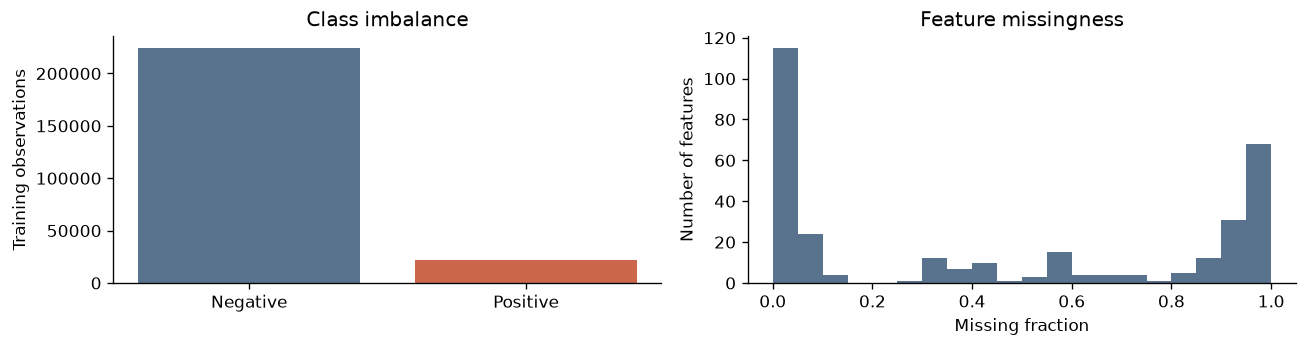

In [6]:
# Create one figure with three plots arranged in a row.
fig, axes = plt.subplots(1, 2, figsize=(11, 3))

# Plot 1: count negative and positive training labels.
negative_count = np.sum(training_labels == 0)
positive_count = np.sum(training_labels == 1)

axes[0].bar(
    ["Negative", "Positive"],
    [negative_count, positive_count],
    color=["#59738f", "#cd674b"],)
axes[0].set_ylabel("Training observations")
axes[0].set_title("Class imbalance")

# Plot 2: show missing-value fractions across features.
axes[1].hist(missing_rates, bins=20, color="#59738f")
axes[1].set_xlabel("Missing fraction")
axes[1].set_ylabel("Number of features")
axes[1].set_title("Feature missingness")

# Arrange the plots, save the figure, and display it.
fig.tight_layout()
fig.savefig(FIGURES / "data_overview.png")
plt.show()

## 3. Prepare features using one workflow

In [7]:
# This is the predefined set of features that are always included in the compact feature set.
CORE = """_AGE80 SEX GENHLTH PHYSHLTH MENTHLTH POORHLTH HLTHPLN1 PERSDOC2
MEDCOST CHECKUP1 BPHIGH4 BPMEDS BLOODCHO CHOLCHK TOLDHI2 CVDSTRK3 ASTHMA3
ASTHNOW CHCSCNCR CHCOCNCR CHCCOPD1 HAVARTH3 ADDEPEV2 CHCKIDNY DIABETE3
MARITAL EDUCA RENTHOM1 VETERAN3 EMPLOY1 INCOME2 INTERNET QLACTLM2 USEEQUIP
BLIND DECIDE DIFFWALK DIFFDRES DIFFALON _SMOKER3 _BMI5 _PACAT1 _PASTRNG
PNEUVAC3 FLUSHOT6 _DRNKWEK _FRUTSUM _VEGESUM""".split()
print(CORE)

['_AGE80', 'SEX', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'PERSDOC2', 'MEDCOST', 'CHECKUP1', 'BPHIGH4', 'BPMEDS', 'BLOODCHO', 'CHOLCHK', 'TOLDHI2', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNCR', 'CHCOCNCR', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'CHCKIDNY', 'DIABETE3', 'MARITAL', 'EDUCA', 'RENTHOM1', 'VETERAN3', 'EMPLOY1', 'INCOME2', 'INTERNET', 'QLACTLM2', 'USEEQUIP', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', '_SMOKER3', '_BMI5', '_PACAT1', '_PASTRNG', 'PNEUVAC3', 'FLUSHOT6', '_DRNKWEK', '_FRUTSUM', '_VEGESUM']


In [8]:
# Exclude survey administration fields and post-event rehabilitation questions.
admin = names[names.index("QSTVER") : names.index("_LLCPWT") + 1] # admin fields are contiguous in the CSV file.
EXCLUDED = set(names[:26] + admin + ["HAREHAB1", "STREHAB1"]) # exclude the first 26 columns, the admin fields, and the two rehab questions.
print(EXCLUDED)

{'_STRWT', '_CPRACE', 'COLGHOUS', '_WT2RAKE', 'IDAY', 'STATERES', 'NUMADULT', 'CTELNUM1', 'CCLGHOUS', 'HAREHAB1', 'IDATE', '_CRACE1', 'QSTLANG', '_STSTR', '_DUALCOR', 'FMONTH', 'DISPCODE', '_CLLCPWT', 'NUMWOMEN', '_STATE', 'CADULT', '_PSU', 'IYEAR', 'MSCODE', 'STREHAB1', 'PVTRESD1', '_CHISPNC', 'LANDLINE', 'CELLFON3', 'CELLFON2', '_RAWRAKE', 'SEQNO', 'NUMMEN', 'CSTATE', 'HHADULT', 'LADULT', '_LLCPWT', 'CTELENUM', 'IMONTH', 'PVTRESD2', 'QSTVER', '_DUALUSE'}


In [9]:
def make_features(raw, rules):
    """Build the same feature matrix for every candidate."""
    learning = rules is None

    # 1. Determine which columns to include in the feature matrix during the training phase.
    if learning:
        rules = {"features": []}
        columns = []

        # Iterate over all feature names and their corresponding column indices.
        for j, name in enumerate(names):

            # Exclude the columns that are explicitly blacklisted in the EXCLUDED set.
            if name in EXCLUDED:
                continue
            vals = raw[:, j]
            valid_vals = vals[np.isfinite(vals)]
            
            # Keep the column only if it has more than 10% valid (non-missing) values 
            # and contains at least 2 unique valid values (to avoid useless constants).
            if len(valid_vals) > 0.1 * len(vals) and len(np.unique(valid_vals)) > 1:
                columns.append(j)
    else:
        # If in validation/test phase, strictly reuse the columns determined during training.
        columns = [f["column"] for f in rules["features"]]

    # 2. Perform feature transformations column by column.
    blocks = [np.ones((len(raw), 1), dtype=np.float32)]  # Initialize with the intercept term.
    groups = ["compact"] 

    for position, j in enumerate(columns):
        values = raw[:, j].copy()
        name = names[j]

        # Apply specific domain-knowledge cleaning rules to known survey variables.
        if name in ("PHYSHLTH", "MENTHLTH", "POORHLTH"):
            values[values == 88] = 0
            values[np.isin(values, [77, 99])] = np.nan
        elif name == "_DRNKWEK":
            values[values == 99900] = np.nan
            
        missing = ~np.isfinite(values)

        if learning:
            observed = values[~missing]
            levels, counts = np.unique(observed, return_counts=True)
            feature = {"column": j}
            
            if len(levels) <= 16:
                feature["kind"] = "category"
                # Treat as a categorical feature. Drop the most frequent category 
                # to use as the baseline/reference level (using list.pop() is more Pythonic).
                levels = list(levels)
                levels.pop(np.argmax(counts)) 
                feature["levels"] = levels
            else:
                # Treat as a numeric feature. Store median for imputation, and 
                # the 1st/99th percentiles for robust scaling and clipping.
                feature["kind"] = "numeric"
                feature["median"] = float(np.median(observed))
                lower, upper = np.quantile(observed, [0.01, 0.99])
                feature["lower"] = float(lower)
                feature["upper"] = float(upper)
                feature["scale"] = float(max(upper - lower, 1))
                
            rules["features"].append(feature)
        else:
            feature = rules["features"][position]

        # Apply the learned encodings to the data.
        if feature["kind"] == "category":
            # Use numpy broadcasting to generate a one-hot encoded matrix directly and efficiently.
            encoded = (values[:, None] == feature["levels"]).astype(np.float32)
        else:
            # Impute missing values with the learned median, clip extreme outliers, and scale.
            filled = np.where(missing, feature["median"], values)
            clipped = np.clip(filled, feature["lower"], feature["upper"])
            encoded = ((clipped - feature["median"]) / feature["scale"])[:, None]

        # Append the processed feature array and a missing-value indicator column to our blocks.
        blocks.extend([encoded.astype(np.float32), missing[:, None].astype(np.float32)])
        
        # Categorize the feature into 'compact' or 'broad' groups for model architecture tuning later.
        group = "compact" if name in CORE else "broad"
        groups.extend([group] * (encoded.shape[1] + 1))

    # 3. Construct explicit interaction features.
    # Hard-coded rules to extract specific demographics and health metrics.
    age = np.minimum((raw[:, names.index("_AGE80")] - 18) // 10, 6)
    sex = raw[:, names.index("SEX")]
    health = raw[:, names.index("GENHLTH")]
    
    pairs = [
        (age, sex, range(7), [1, 2]),
        (age, health, range(7), range(1, 6)),
        (sex, health, [1, 2], range(1, 6)),
    ]
    
    for f1, f2, l1, l2 in pairs:
        # Use itertools.product to flatten the nested loops for generating pair interactions, 
        # making the code much more compact and readable.
        interactions = [(f1 == v1) & (f2 == v2) for v1, v2 in itertools.product(l1, l2)]
        blocks.append(np.column_stack(interactions).astype(np.float32))
        groups.extend(["interaction"] * len(interactions))

    # 4. Concatenate matrices and drop zero-variance columns.
    # Use np.concatenate along axis 1, which is strictly preferred for merging lists of 2D arrays.
    matrix = np.concatenate(blocks, axis=1) 
    
    if learning:
        # Keep columns where the peak-to-peak (ptp) variance is greater than 0 (i.e., not a constant).
        keep = np.ptp(matrix, axis=0) > 0  
        keep[0] = True  # Always keep the intercept, even though its variance is zero.
        
        # Use the highly recognizable np.where()[0] to find the indices of the columns to keep.
        rules["keep"] = np.where(keep)[0].tolist() 
        
        # Organize the remaining valid column indices into logical sets for experimentation.
        groups_arr = np.array(groups)[keep]
        rules["columns"] = {
            "Compact": np.where(groups_arr == "compact")[0].tolist(),
            "Broad": np.where(groups_arr != "interaction")[0].tolist(),
            "Interactions": list(range(len(groups_arr))),
        }

    # Return the fully constructed feature matrix (ensuring contiguous memory) and the learned rules.
    return np.ascontiguousarray(matrix[:, rules["keep"]]), rules

## 4. Metrics and logistic regression

Compute F1 and accuracy from the confusion counts. Logistic regression uses the same regularized loss and L-BFGS updates as the original code.

In [10]:
def metrics(target, prediction):
    """Return F1, accuracy, and confusion-matrix counts for the positive class."""

    # positive: boolean array indicating which samples are positive (label 1)
    # predicted: boolean array indicating which samples are predicted as positive (label 1)
    positive = np.asarray(target) == 1
    predicted = np.asarray(prediction, dtype=bool)

    # Calculate true positives (tp), false positives (fp), false negatives (fn), and true negatives (tn).
    tp = int(np.sum(predicted & positive))
    fp = int(np.sum(predicted & ~positive))
    fn = int(np.sum(~predicted & positive))
    tn = len(target) - tp - fp - fn

    # Calculate F1 score and accuracy, ensuring no division by zero.
    return {
        "f1": 2 * tp / max(2 * tp + fp + fn, 1),
        "accuracy": (tp + tn) / len(target),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,}


def objective_gradient(matrix, target, weights, lam):

    # 1. Compute the logits (linear combination of features and weights).
    logits = (matrix @ weights.astype(np.float32)).astype(float)

    # 2. Compute the predicted probabilities using the logistic function.
    # logaddexp is used for numerical stability when computing the logistic function.
    probability = np.exp(-np.logaddexp(0, -logits))

    # 3. compute the mean logistic loss and its gradient with L2 regularization.
    loss = np.mean(np.logaddexp(0, logits) - target * logits)

    # Add L2 regularization to the loss, excluding the intercept term (weights[0]).
    loss += lam * (weights[1:] @ weights[1:])

    # 4. Compute the gradient of the loss with respect to the weights.
    gradient = (matrix.T @ (probability - target).astype(np.float32)).astype(float)
    gradient /= len(target)
    gradient[1:] += 2 * lam * weights[1:]

    # 5. Return the loss and gradient.
    return loss, gradient

In [11]:
def fit_logistic(matrix, target, lam):
    """Fit L2 logistic regression with limited-memory BFGS and line search."""
    
    # 1. Initialize weights. Set the intercept (weights[0]) to the log-odds 
    # of the target mean. This is a smart initialization that speeds up convergence.
    weights = np.zeros(matrix.shape[1])
    weights[0] = np.log(target.mean() / (1 - target.mean()))
    
    # 2. Compute the initial loss and gradient, and initialize the L-BFGS history buffer.
    loss, gradient = objective_gradient(matrix, target, weights, lam)
    history = []  # Recent (weight change, gradient change, inverse curvature).

    # 3. Begin the main optimization loop (maximum of 200 iterations).
    for _ in range(200):
        
        # 4. Convergence check: stop if the maximum absolute gradient component is sufficiently small.
        if np.max(np.abs(gradient)) < 2e-5:
            break

        # 5. Compute the search direction using the L-BFGS two-loop recursion.
        # This approximates the inverse Hessian multiplied by the gradient.
        direction = gradient.copy()
        alphas = []
        
        # First pass (backward loop): iterate backwards through the history.
        for weight_change, gradient_change, rho in reversed(history):
            alpha = rho * (weight_change @ direction)
            alphas.append(alpha)
            direction -= alpha * gradient_change
            
        # Scale the initial Hessian approximation using the most recent iteration's data.
        if history:
            weight_change, gradient_change, _ = history[-1]
            scale = (weight_change @ gradient_change) / (
                gradient_change @ gradient_change
            )
            direction *= scale
            
        # Second pass (forward loop): iterate forwards through the history.
        for (weight_change, gradient_change, rho), alpha in zip(
            history, reversed(alphas)
        ):
            direction += weight_change * (alpha - rho * (gradient_change @ direction))
            
        # Negate the direction so it points towards the minimum (descent direction).
        direction *= -1

        # 6. Perform a backtracking line search to find an acceptable step size.
        # The Armijo condition ensures a sufficient decrease in the objective loss.
        step = 1.0
        for _ in range(20):
            trial = weights + step * direction
            new_loss, new_gradient = objective_gradient(matrix, target, trial, lam)
            
            # If the new loss is sufficiently smaller, accept the step.
            if new_loss <= loss + 1e-4 * step * (gradient @ direction):
                break
            step *= 0.5
        else:
            # If the line search fails to find a valid step after 20 tries, exit the loop.
            break  # Keep the last accepted weights.

        # 7. Update the L-BFGS history with the latest weight and gradient changes.
        weight_change = trial - weights
        gradient_change = new_gradient - gradient
        curvature = weight_change @ gradient_change
        
        # Ensure the curvature condition is met before storing the updates.
        # Keep only the 10 most recent updates (limited memory).
        if curvature > 1e-12:
            history.append((weight_change, gradient_change, 1 / curvature))
            history = history[-10:]
            
        # 8. Update the current weights, loss, and gradient for the next iteration.
        weights, loss, gradient = trial, new_loss, new_gradient
        
    # 9. Return the optimized weights.
    return weights

## 5. Compare the nine candidates

Build the training and tuning matrices once. Compare three feature subsets and three regularization strengths, and choose a threshold on the tuning data.

In [12]:
# 1. Preprocess the raw data into feature matrices.
# Train the preprocessing rules on the training (fit) subset, 
# then apply the exact same rules to the validation (tune) subset.
X, rules = make_features(x[fit_idx], None)
V, _ = make_features(x[tune_idx], rules)

# 2. Define candidate classification thresholds and initialize storage.
# Thresholds range from 0.10 to 0.40 (in 0.005 increments), plus the standard 0.5.
thresholds = np.r_[np.round(np.arange(0.10, 0.401, 0.005), 3), 0.5]
rows = []
models = {}

# 3. Iterate through different predefined feature combinations (e.g., Compact, Broad, Interactions).
for feature_set, columns in rules["columns"].items():
    # Extract contiguous arrays for the current subset of columns to speed up matrix operations.
    X_model = np.ascontiguousarray(X[:, columns])
    V_model = np.ascontiguousarray(V[:, columns])
    
    # 4. Train models across different L2 regularization strengths (lambda).
    for lam in (1e-5, 1e-4, 1e-3):
        # Fit the logistic regression model on the training data.
        weights = fit_logistic(X_model, y[fit_idx], lam)
        
        # 5. Generate predictions (probabilities) on the validation (tune) set.
        logits = (V_model @ weights.astype(np.float32)).astype(float)
        scores = np.exp(-np.logaddexp(0, -logits))

        # 6. Evaluate all candidate thresholds to find the optimal decision boundary.
        curve = []
        for threshold in thresholds:
            result = metrics(y[tune_idx], scores >= threshold)
            curve.append({"threshold": float(threshold), **result})
            
        # The best threshold is chosen primarily by F1 score, then accuracy, 
        # and finally preferring a higher threshold in case of a tie.
        best_threshold = max(
            curve,
            key=lambda result: (result["f1"], result["accuracy"], result["threshold"]),
        )

        # 7. Record the best metrics and save the model weights and configuration for this hyperparameter set.
        key = f"{feature_set} ({lam:g})"
        rows.append({"model": key, "lambda": lam, **best_threshold})
        models[key] = {"weights": weights, "feature_set": feature_set, "curve": curve}

# 8. Select the overall best model across all feature sets and lambdas.
# The winner is chosen based on the highest tuning F1 score, breaking ties with accuracy.
best = max(rows, key=lambda result: (result["f1"], result["accuracy"]))
chosen = models[best["model"]]
print(f"Selected model: {best['model']}, threshold: {best['threshold']:.3f}")

# 9. Clean up large matrices from memory to free up RAM.
del X, V, X_model, V_model

Selected model: Broad (0.0001), threshold: 0.185


## 6. Evaluate the selected model

Apply the training rules to the holdout rows and evaluate the selected candidate. The threshold curve uses tuning data; the confusion matrix uses holdout data.

Holdout F1: 0.4385, accuracy: 0.8667


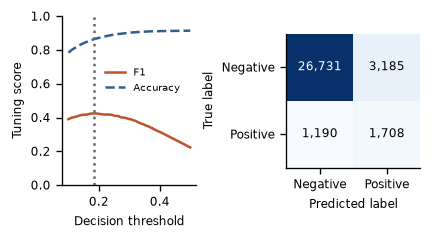

In [13]:
# 1. Preprocess the holdout (test) set using the exact rules learned from the training set.
H, _ = make_features(x[hold_idx], rules)

# 2. Extract only the columns required by the best model's selected feature set, 
# and store it contiguously in memory for faster matrix multiplication.
H = np.ascontiguousarray(H[:, rules["columns"][chosen["feature_set"]]])

# 3. Compute the logits and predicted probabilities for the holdout set 
# using the optimized weights of the best model.
logits = (H @ chosen["weights"].astype(np.float32)).astype(float)
hold_scores = np.exp(-np.logaddexp(0, -logits))

# 4. Evaluate the model's final performance on the holdout set 
# using the optimal decision threshold discovered during the tuning phase.
final_metrics = metrics(y[hold_idx], hold_scores >= best["threshold"])
print(
    f"Holdout F1: {final_metrics['f1']:.4f}, accuracy: {final_metrics['accuracy']:.4f}"
)

# Free up memory by deleting the holdout matrix.
del H

# 5. Set up a visualization figure with two subplots: 
# a tuning curve (left) and a confusion matrix (right).
with plt.rc_context({"font.size": 7}):
    fig, axes = plt.subplots(1, 2, figsize=(3.5, 1.9))
    
    # 6. Plot the tuning threshold curve (Left Subplot).
    # This visualizes how F1 score and Accuracy change across different thresholds.
    for metric, color, style in [("f1", "#bd542d", "-"), ("accuracy", "#315f8c", "--")]:
        axes[0].plot(
            thresholds,
            [r[metric] for r in chosen["curve"]],
            style,
            label=metric.upper() if metric == "f1" else "Accuracy",
            color=color,
        )
    # Add a vertical dotted line to indicate the final chosen threshold.
    axes[0].axvline(best["threshold"], color="0.4", linestyle=":")
    axes[0].set(xlabel="Decision threshold", ylabel="Tuning score", ylim=(0, 1))
    axes[0].legend(fontsize=6, frameon=False, loc="center", bbox_to_anchor=(0.60, 0.62))

    # 7. Plot the holdout confusion matrix (Right Subplot).
    # Extract True Negatives, False Positives, False Negatives, and True Positives into a 2x2 grid.
    counts = np.array([final_metrics[k] for k in ("tn", "fp", "fn", "tp")]).reshape(
        2, 2
    )
    axes[1].imshow(counts, cmap="Blues")
    
    # Iterate through the 2x2 grid to add the exact counts as text inside the cells.
    for i in range(2):
        for j in range(2):
            # Dynamically change the text color to white if the cell background is dark, 
            # or black if it is light, ensuring readability.
            color = "white" if counts[i, j] > counts.max() * 0.5 else "black"
            axes[1].text(
                j, i, f"{counts[i, j]:,}", ha="center", va="center", color=color
            )
            
    # Apply standard labels to the axes of the confusion matrix.
    axes[1].set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        xlabel="Predicted label",
        ylabel="True label",
    )
    
    # 8. Adjust layout spacing, save the figure to disk in high resolution, and display it.
    fig.tight_layout(pad=0.5)
    fig.savefig(FIGURES / "evaluation.png", dpi=220)
    plt.show()

## 7. Refit and export

Learn the same preprocessing rules on all labeled rows, refit the selected model, and generate the competition CSV and model weights. Running this notebook writes those outputs and the two figures in the project folder.

In [14]:
# 1. Retrain the preprocessing rules on the *entire* labeled dataset 
# (combining train, tune, and holdout sets) to maximize the amount of learning data.
X_full, final_rules = make_features(x, None)

# 2. Extract only the subset of columns required by the previously chosen best feature set, 
# and ensure contiguous memory layout for efficient matrix multiplication.
columns = final_rules["columns"][chosen["feature_set"]]
X_full = np.ascontiguousarray(X_full[:, columns])

# 3. Train the final logistic regression model on this complete dataset 
# using the optimal L2 regularization penalty (lambda) discovered earlier.
final_weights = fit_logistic(X_full, y, best["lambda"])
del X_full  # Free up memory before processing the test set.

# 4. Preprocess the unseen competition test set. 
# It is critical to pass the `final_rules` learned from the full dataset so the transformations match exactly.
X_test, _ = make_features(x_test, final_rules)
X_test = np.ascontiguousarray(X_test[:, columns])

# 5. Compute the logits and final predicted probabilities for the test set 
# using the newly trained final model weights.
logits = (X_test @ final_weights.astype(np.float32)).astype(float)
competition_scores = np.exp(-np.logaddexp(0, -logits))

# 6. Convert the probabilities into hard class labels (1 for positive, -1 for negative) 
# by applying the best decision threshold found during the tuning phase.
predictions = np.where(competition_scores >= best["threshold"], 1, -1)

# 7. Export the test set predictions to a CSV file formatted for the competition submission.
create_csv_submission(test_ids, predictions, str(ROOT / "submission.csv"))

# 8. Save the final model weights and chosen threshold into a compressed Numpy file 
# for future deployment, scoring, or reproducibility.
np.savez_compressed(
    RESULTS / "model.npz", weights=final_weights, threshold=best["threshold"]
)

# Print a final success message summarizing the number of predictions made.
print(f"Saved {len(predictions):,} test predictions to submission.csv")

Saved 109,379 test predictions to submission.csv
